# Multi Layer Perceptron - Part 2

In [1]:
# Makemore Part 3 - continuing MLP journey
# We will PyTorchify much of the code

In [2]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# pick the GPU if available (on AMD/ROCm builds of PyTorch the GPU is also exposed as 'cuda')
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('using device:', device, f'({torch.cuda.get_device_name(0)})' if device.type == 'cuda' else '')
device = torch.device('cpu')
# Setting it to use CPU as for these small models, cpu is faster than overhead for moving data to GPU

using device: cpu 


In [4]:
import os
data_path = '/content/sample_data/names.txt' if os.path.exists('/content/sample_data/names.txt') else 'names.txt'  # Colab or local
words = open(data_path).read().splitlines()

In [5]:
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [6]:
len(words)

32033

In [7]:
# build vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
vocab_size = len(itos)
print(stoi)
print(itos)

{'a': 1, 'b': 2, 'c': 3, 'd': 4, 'e': 5, 'f': 6, 'g': 7, 'h': 8, 'i': 9, 'j': 10, 'k': 11, 'l': 12, 'm': 13, 'n': 14, 'o': 15, 'p': 16, 'q': 17, 'r': 18, 's': 19, 't': 20, 'u': 21, 'v': 22, 'w': 23, 'x': 24, 'y': 25, 'z': 26, '.': 0}
{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [8]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):
    X, Y = [], []

    for w in words:
        # print(w)
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '--->', itos[ix])
            context = context[1:] + [ix]    # crop and append

    X = torch.tensor(X, device=device)
    Y = torch.tensor(Y, device=device)
    print(X.shape, Y.shape)
    return X, Y

In [9]:
import random
random.seed(42)
random.shuffle(words)

n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])            # 80%
Xdev, Ydev = build_dataset(words[n1:n2])        # 10%
Xte, Yte = build_dataset(words[n2:])            # 10%

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


Your picture has the direction reversed. Normalization ($\mu$, $\sigma$) is what forces mean 0 / std 1, at every training step. Then $\gamma$ and $\beta$ move the values away from 0/1, by whatever amount the network learns is useful. $\gamma$ and $\beta$ don’t restore 0/1. They’re the controlled way out of it.

The pipeline for one neuron, every training step
$$\underbrace{z}_{\text{raw}} \;\xrightarrow{\;\text{standardize with } \mu_B,\ \sigma_B\;}\; \underbrace{\hat{x} = \frac{z-\mu_B}{\sigma_B}}_{\text{always mean 0, std 1}} \;\xrightarrow{\;\text{scale/shift with } \gamma,\ \beta\;}\; \underbrace{y = \gamma\hat{x} + \beta}_{\text{mean } \beta,\ \text{std } \lvert\gamma\rvert} \;\xrightarrow{\;\tanh\;}\; a$$
$\hat{x}$ has mean 0 and std 1 within the batch, no matter what the weights are. That’s guaranteed by the arithmetic.
$y$ then has mean exactly $\beta$ and std exactly $|\gamma|$.
tanh sees $y$, not $\hat{x}$.
The quantities and their jobs
Quantity	How it’s obtained	When it’s used	Job
$\mu_B$, $\sigma_B$	computed fresh from the current batch, every training step (not learned)	training forward pass	wipe out whatever mean and scale $z$ happens to have
$\gamma$, $\beta$	learned by backprop, initialized to 1 and 0	training and inference	set the mean and spread that tanh actually receives
$\mu_{\text{running}}$, $\sigma_{\text{running}}$	averaged from $\mu_B$, $\sigma_B$ during training (not learned)	inference only, as a stand-in for $\mu_B$, $\sigma_B$	make predictions independent of the batch

So it’s really 6 quantities per neuron, not 4. Your idea that $\mu$ and $\sigma$ are only used at initialization is the part to drop. Batch statistics are recomputed every step. The “only at initialization” idea applies to $\gamma = 1$, $\beta = 0$: those are where training starts, which is why the layer initially just outputs $\hat{x}$.

A worked example with one neuron and a batch of 4

Raw pre-activations: $z = (2,\ 4,\ 6,\ 8)$, so $\mu_B = 5$ and $\sigma_B = \sqrt{5} \approx 2.236$.

$$\hat{x} = (-1.342,\ -0.447,\ 0.447,\ 1.342)$$

Suppose training has learned $\gamma = 2$ and $\beta = 0.5$:

$$y = 2\hat{x} + 0.5 = (-2.183,\ -0.394,\ 1.394,\ 3.183)$$

That has mean 0.5 and std 2, which is a wider, shifted input to tanh. The network chose this.

Predict before reading on: the weights now grow 10× so that $z = (20, 40, 60, 80)$. What does $y$ become?

It’s unchanged. $\mu_B = 50$ and $\sigma_B = 22.36$, so $\hat{x}$ is the same $(-1.342, \ldots)$, and therefore $y$ is the same too.

Why split it this way

Without batch norm, the mean and spread going into tanh depend on the weights $W$ and on every layer before them, and all of that drifts during training. That’s how neurons end up saturated.

With batch norm, the jobs separate:

$W$ (and earlier layers) decide only the relative pattern: which examples are above or below average for this neuron, and by how much in units of std.
$\gamma$, $\beta$ decide the absolute mean and spread that tanh receives, through two direct parameters.

So “the network might want a more spread-out distribution” means the network can learn $\gamma = 2$ directly, instead of hoping the weights happen to produce that spread. This is also why Karpathy drops b1 from the linear layer: subtracting $\mu_B$ cancels any bias, and $\beta$ does that job instead.

One more fact: if the network learned $\gamma = \sigma_B$ and $\beta = \mu_B$, the layer would output $z$ unchanged. So batch norm never takes away expressiveness. At worst, it can learn to undo itself.

In [10]:
n_embed = 10    # the dimensionality of the character embeddings
n_hidden = 200  # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((vocab_size, n_embed),              generator=g)
W1 = torch.randn((n_embed * block_size, n_hidden),  generator=g) * (5/3) / ((n_embed * block_size) ** 0.5)
# b1 = torch.randn(n_hidden,                          generator=g) * 0.01
W2 = torch.randn((n_hidden, vocab_size),            generator=g) * 0.01
b2 = torch.randn(vocab_size,                        generator=g) * 0

# Batch Norm Parameters
bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros((1, n_hidden))

bnmean_running = torch.zeros((1, n_hidden))
bnstd_running = torch.ones((1, n_hidden))
# We intialize the running avg mean and running avg std as this beacuse of the following
# In the beginning, because of the we initialized W1 and b1, hpreact will be Unit Gaussian, so the mean of hpreact will be roughly 0 and std dev will be roughly 1.

parameters = [C, W1, W2, b2, bngain, bnbias]
print(sum(p.nelement() for p in parameters)) # number of parameters in total
for p in parameters:
  p.data = p.data.to(device)   # move parameters to the GPU (init stays on CPU generator for reproducibility)
  p.requires_grad = True

12097


In [11]:
# Same optimization as last time but we track moving average mean and std deviation. Maybe this is the exponenetial moving average, I dont know precisely but we are tracking a moving average for sure.
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):   # Make this 10000

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g).to(device)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X,Y

    # forward pass
    emb = C[Xb] # [32, 3, 2]
    embcat = emb.view(emb.shape[0], -1) # concatenate the vectors
    # ====================================================
    # -------------- Linear Layer -----------------------
    hpreact = embcat @ W1  #+ b1 ( this is what changed from above) # hidden layer pre-activation

    # -------------- BatchNorm Layer --------------------
    bnmeani = hpreact.mean(dim=0, keepdims=True)
    bnstdi = hpreact.std(dim=0, keepdims=True)
    hpreact = bngain * (hpreact - bnmeani) / bnstdi + bnbias

    with torch.no_grad():
        bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
        bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi

    # --------------- Non Linearity ----------------------
    h = torch.tanh(hpreact)    # hidden layer
    # ====================================================
    logits = h @ W2 + b2                       # output layer
    loss = F.cross_entropy(logits,Yb)

    #backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01    # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    if i % 10000 == 0:  # print every once in a while
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().detach())  # keep on GPU; calling .item() every step forces a GPU->CPU sync

      0/ 200000: 3.3239
  10000/ 200000: 2.0322
  20000/ 200000: 2.5675
  30000/ 200000: 2.0125
  40000/ 200000: 2.2446
  50000/ 200000: 1.8897
  60000/ 200000: 2.0785
  70000/ 200000: 2.3681
  80000/ 200000: 2.2918
  90000/ 200000: 2.0238
 100000/ 200000: 2.3673
 110000/ 200000: 2.3132
 120000/ 200000: 1.6414
 130000/ 200000: 1.9311
 140000/ 200000: 2.2231
 150000/ 200000: 2.0027
 160000/ 200000: 2.0997
 170000/ 200000: 2.4949
 180000/ 200000: 2.0198
 190000/ 200000: 2.1707


In [12]:
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(selection):
    x,y = {
        'train': (Xtr, Ytr),
        'val': (Xdev, Ydev),
        'test':  (Xte, Yte)
    }[selection]

    # N           ->>   B (batch_size)
    # block_size  ->>   T
    # n_embed     ->>   C (embedding_dim)

    emb = C[x] # [N, block_size, n_embed], equiv to [B, T, C]
    embcat = emb.view(emb.shape[0], -1) # concatenate into [N, block_size* n_embed], equiv to [B, T*C]
    hpreact = embcat @ W1
    hpreact = bngain * ((hpreact - bnmean_running) / bnstd_running) + bnbias
    h = torch.tanh(hpreact)    # [N, n_hidden]
    logits = h @ W2 + b2                # [N, vocab_size]
    loss = F.cross_entropy(logits,y)
    print(selection, loss.item())

split_loss('train')
split_loss('val')

train 2.0674145221710205
val 2.1056840419769287


In [13]:
# We want Rougly gausisan outputs/activations throughout the neural net.


## 22. Summary: Importance of Activation and Gradient Statistics

The central theme of this section is understanding the statistics of activations and gradients in neural networks.

This becomes increasingly important as neural networks become larger and deeper.

### 1. Controlling the Output Layer

We first examined the output layer and saw that poorly initialized activations can produce extremely confident but incorrect predictions.

This leads to hockey-stick-shaped loss curves, where the initial training steps are wasted correcting these extreme predictions.

By fixing the initialization, we get a better final loss because the network spends less time doing this wasteful work.

### 2. Controlling Activations Throughout the Network

We also saw that activations need to remain within reasonable ranges.

We don't want them to:
- Vanish toward zero.
- Explode toward infinity.
- Saturate nonlinear activation functions such as `tanh`.

Ideally, we want reasonably well-behaved, roughly Gaussian activations throughout the network.

### 3. Weight Initialization

We explored how to scale weight matrices and initialize biases so that activations remain well-behaved from the beginning of training.

Careful initialization gave us a significant improvement in training.

However, manually controlling activation distributions becomes extremely difficult in deeper networks with many different types of layers and operations.

### 4. Normalization Layers

This motivated the introduction of normalization layers.

Some commonly used normalization techniques are:

- Batch normalization.
- Layer normalization.
- Instance normalization.
- Group normalization.

The basic idea is to normalize activations using their mean and standard deviation.

We studied batch normalization, which:
1. Centers activations by subtracting their batch mean.
2. Scales them by dividing by their batch standard deviation.
3. Introduces learnable gain and bias parameters.
4. Maintains running estimates of the mean and standard deviation for inference.

All of this makes batch normalization more involved than simply standardizing the activations.

### 5. Why Batch Normalization Can Be Problematic

Batch normalization couples training examples during the forward pass because the statistics of one example depend on the other examples in its batch.

This introduces complications and can cause unexpected bugs.

The instructor strongly recommends avoiding batch normalization when possible, particularly because alternatives such as layer normalization and group normalization have become more common in modern deep learning.

Nevertheless, batch normalization was extremely influential when introduced around 2015 because it made training much deeper neural networks significantly more reliable.

Its fundamental strength is its ability to control activation statistics throughout the network.



# PyTorchifying✨

In [14]:
# Let's train a deeper network

class Linear:

    def __init__(self, fan_in, fan_out, bias = True):
        self.weight = torch.randn((fan_in, fan_out), generator=g) / fan_in **0.5
        self.bias = torch.zeros(fan_out) if bias else None
        # The default we are using is Gaussian, Pytorch uses Uniform

        # runtime attributes
        self.out = None     # forward output (activation)

    def __call__(self, x):
        self.out = x @ self.weight
        if self.bias is not None:
            self.out += self.bias
        return self.out

    def parameters(self):
        return [self.weight] + ([] if self.bias is None else [self.bias])

    # There are 2 parameters self.weight and self.bias. They are arranged as follows ->> params = [self.weight, self.bias]

In [15]:
class BatchNorm1d:

    def __init__(self, dim, eps=1e-5, momentum=0.1):
        self.eps = eps
        self.momentum = momentum
        self.training = True
        # parameters (trained with backprop)
        self.gamma = torch.ones(dim) # dim is the dimension of the hidden layer
        self.beta = torch.zeros(dim) # on which this Normalization is applied
        # buffers (trained with a running 'momentum update')
        self.running_mean = torch.zeros(dim)
        self.running_var = torch.ones(dim)

    def __call__(self, x):
        # calculate the forward pass
        if self.training:
            # If we are training we will caluate the mean and variance for each of the batches we are running the training on
            xmean = x.mean(0, keepdims=True) # can use keepdim or keepdims
            xvar = x.var(0, keepdim=True, unbiased=True) # batch variance
        else: # seems weird, like if and else conditions are flipped.
            xmean = self.running_mean
            xvar = self.running_var
        xhat = (x-xmean) / torch.sqrt(xvar + self.eps) # normalize to unit variance
        self.out = self.gamma * xhat + self.beta
        # update the buffers (exponential moving average)
        if self.training:
            with torch.no_grad():
                self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
                self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar
        return self.out

    def parameters(self):
        return [self.gamma, self.beta]

In [16]:
class Tanh:
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out
    def parameters(self):
        return []

In [24]:
n_embed = 10 # the dimensionality of the character embedding vectors
n_hidden = 100 # the number of neurons in the hidden layer of the MLP
g = torch.Generator().manual_seed(2147483647)

C = torch.randn((vocab_size, n_embed),              generator=g)


layers = [
    Linear(n_embed * block_size, n_hidden, bias = False), Tanh(),
    Linear(            n_hidden, n_hidden, bias = False), Tanh(),
    Linear(            n_hidden, n_hidden, bias = False), Tanh(),
    Linear(            n_hidden, n_hidden, bias = False), Tanh(),
    Linear(            n_hidden, n_hidden, bias = False), Tanh(),
    Linear(            n_hidden, vocab_size, bias = False)
]

In [25]:
with torch.no_grad():
    # last layer: make less confident
    layers[-1].weight *= 0.1
    # all other layers: apply gain
    for layer in layers[:-1]:
        if isinstance(layer, Linear):
            layer.weight *= 5/3

parameters = [C] + [p for layer in layers for p in layer.parameters()]
print(sum(p.nelement() for p in parameters))     # number of parametrs in total
for p in parameters:
    p.requires_grad = True

45970


In [31]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []
ud = []

for i in range(max_steps):

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X, Y

    # forward pass
    emb = C[Xb] #embed characters into vectors
    x = emb.view(emb.shape[0], -1) # concatenate the vectors
    for layer in layers:
        x = layer(x)
    loss = F.cross_entropy(x, Yb) # loss function

    # backward pass
    for layer in layers:
        layer.out.retain_grad() # AFTER_DEBUG: would take out retain_graph
        # Woudldn't this create issues because we need to zero out the gradients before each loop. Where is this stored? is this stored in some separate place ?
        # Ans - This won't retain the gradients on the next iteration. This only retains the gradients after the last iteration. Check below for more

    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 150000 else 0.01 # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    if i % 10000 == 0: # print every once in a while
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())
    with torch.no_grad():
        ud.append([((lr*p.grad).std() / p.data.std()).log10().item() for p in parameters])


    if i >= 1000:
        break # AFTER_DEBUG: would take out obviously to run full optimization

      0/ 200000: 3.2965


In [33]:
# A forward pass changes the output and the loss.backward() of that iteration changes the value in .grad for 'out'
# But PyTorch by default clears the .grad attribute of non-leaf nodes even if its the last iteration and there is not subsequent forward pass.
# This method call will be helpful in that particular scenario, when wea re in the last iteration and Pytorch, by virtua of its default behaviour owuld be trying to lear the .grad of this non-leaf node, but our method call will make Pytorch retain it for our inspection.

Visualize the histograms of the forward pass activations, and specifically at the Tanh layers

layer 1 (      Tanh): mean -0.07, std 0.76, saturated: 22.34%
layer 3 (      Tanh): mean +0.01, std 0.73, saturated: 12.34%
layer 5 (      Tanh): mean +0.00, std 0.75, saturated: 14.88%
layer 7 (      Tanh): mean -0.05, std 0.74, saturated: 13.22%
layer 9 (      Tanh): mean -0.01, std 0.71, saturated: 12.16%


Text(0.5, 1.0, 'activation distribution')

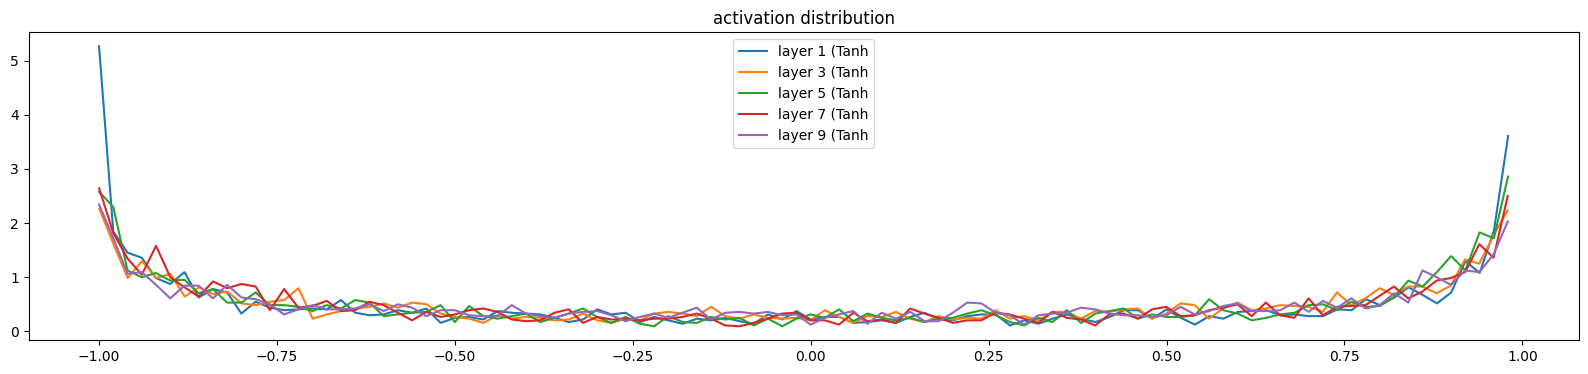

In [34]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out
    print('layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%' % (i, layer.__class__.__name__, t.mean(), t.std(), (t.abs() > 0.97).float().mean()*100))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends);
plt.title('activation distribution')


## 23. Understanding Activation Distributions in a Deep MLP

We now have a deeper neural network consisting of multiple `Linear` and `Tanh` layers.

We want to understand how the activation distributions behave as information propagates through these layers.

### 1. Visualizing Activation Distributions

We plot histograms of the activations produced by each `Tanh` layer.

Each color represents a different layer. The histogram shows how frequently activation values occur across the tensor.

We also measure the percentage of saturated activations:

```python
(t.abs() > 0.97).float().mean() * 100
```

An activation is considered saturated when its absolute value exceeds `0.97`.

With a gain of $5/3$, we observe:

- The first layer has approximately 20% saturation.
- Subsequent layers stabilize.
- With more layers, the standard deviation stabilizes around 0.65.
- Saturation stabilizes around 5%.

This indicates that the activation distributions remain reasonably well-behaved throughout the network.

### 2. What Happens Without Gain?

Recall that our initial weight scaling is:

$$
W = \frac{\text{randn}}{\sqrt{\text{fan_in}}}
$$

This preserves the standard deviation when we have consecutive linear layers.

However, our network contains `Tanh` activations between linear layers.

`Tanh` is a squashing function: it compresses the distribution toward the center.

Consequently, without additional gain:

- The first layer starts with a reasonably good distribution.
- Each subsequent `Tanh` layer slightly contracts the distribution.
- The standard deviation progressively shrinks.
- Eventually, activations approach zero.
- Saturation also approaches zero.

Therefore, we need additional gain to compensate for the contraction introduced by `Tanh`.

### 3. Finding an Appropriate Gain

We experiment with different gain values:

| Gain | Observed behavior |
|---|---|
| 1 | Activations progressively shrink toward zero. |
| 5/3 | Standard deviation stabilizes around 0.65, with approximately 5% saturation. |
| 3 | Activations become excessively saturated. |

A gain of $5/3$ empirically works well for this particular arrangement of linear layers and `Tanh` activations.

It compensates for the contraction caused by `Tanh` without making the activations excessively large.

### 4. Why 5/3?

Karpathy mentions that he does not know the exact mathematical derivation behind the recommended gain of $5/3$ in PyTorch's initialization context.

He experimented with it and observed that it produces very reasonable activation distributions for a sequence of linear and `Tanh` layers.

**Key takeaway:** When stacking multiple linear layers with nonlinear activation functions, preserving variance through weight initialization alone is insufficient. The nonlinearities also affect the activation distribution, so an appropriate gain is needed to compensate for their contraction.


layer 1 (      Tanh): mean +0.000002, std 2.965573e-03
layer 3 (      Tanh): mean +0.000057, std 2.964937e-03
layer 5 (      Tanh): mean -0.000017, std 2.854770e-03
layer 7 (      Tanh): mean +0.000006, std 2.798204e-03
layer 9 (      Tanh): mean +0.000009, std 2.366528e-03


Text(0.5, 1.0, 'gradient distribution')

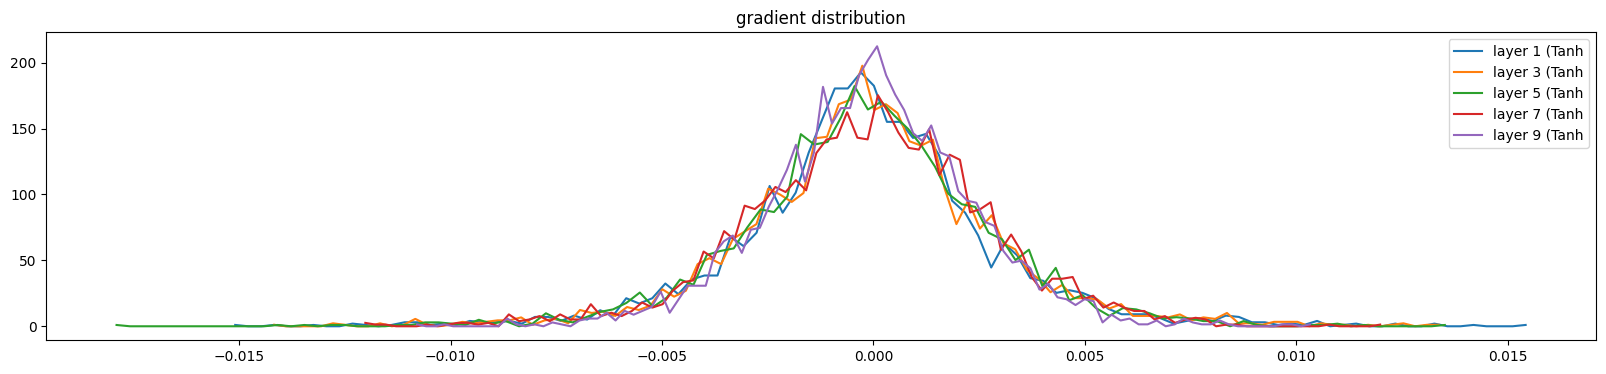

In [35]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out.grad
    print('layer %d (%10s): mean %+f, std %e' % (i, layer.__class__.__name__, t.mean(), t.std()))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends);
plt.title('gradient distribution')



## 24. Monitoring Gradient Distributions

We can perform the same analysis for gradients that we previously performed for activations.

Instead of inspecting `layer.out`, we inspect `layer.out.grad` for every `Tanh` layer.

For each layer, we examine:
- Mean of the gradients.
- Standard deviation of the gradients.
- Histogram of the gradient distribution.

### 1. What Are We Looking For?

Ideally, the gradient distributions across all layers should look roughly similar.

We don't want gradients to:
- **Vanish:** Gradients progressively shrink as they propagate through layers.
- **Explode:** Gradients progressively grow as they propagate through layers.

We want gradients to maintain a reasonably consistent scale throughout the network.

### 2. Effect of an Incorrect Gain

Karpathy experiments with different gain values to demonstrate what happens.

**Gain = 0.5 (Too Small)**

- Activations progressively shrink toward zero.
- Gradients behave poorly in deeper layers.
- Their distributions expand as we move through the network.

**Gain = 3 (Too Large)**

- Activations become excessively saturated.
- Gradient distributions become asymmetric across layers.
- Gradient scales change as we move deeper into the network.

### 3. Why Gain Matters

Without batch normalization, we have to carefully tune initialization gains to maintain healthy distributions in both directions:

| Forward pass | Backward pass |
|---|---|
| Monitor activation distributions | Monitor gradient distributions |
| Avoid shrinking or exploding activations | Avoid vanishing or exploding gradients |
| Avoid excessive `tanh` saturation | Maintain consistent gradient scales |

**Key takeaway:** Good initialization must account for both forward activations and backward gradients. A gain that produces reasonable activation distributions does not automatically guarantee healthy gradient distributions. We need to inspect both.


#---------------------------------------------------------


## 25. Effect of Gain in Deep Linear Networks

Consider a deep network consisting entirely of linear layers, with weight matrices scaled by a gain $g$.

### Gain Greater Than 1

- Activation magnitudes tend to increase as we move through successive layers.
- Gradient magnitudes also tend to increase as they propagate backwards.
- This can lead to exploding activations and gradients.

### Gain Less Than 1

- Activation magnitudes tend to decrease as we move through successive layers.
- Gradient magnitudes also tend to decrease as they propagate backwards.
- This can lead to vanishing activations and gradients.

**Key takeaway:** In a deep linear network, an inappropriate gain can cause both forward activations and backward gradients to explode or vanish. Nonlinearities such as `tanh` introduce additional effects through their derivatives, making gradient propagation more complicated.


#-------------------------------------------------------

**The first case is vanishing gradients.**

Vanishing gradients are defined relative to the direction in which gradients propagate during backpropagation.

Remember:

- Forward pass: Layer 1 → Layer 2 → ... → Layer 7
- Backward pass: Layer 7 → Layer 6 → ... → Layer 1

Suppose we have the following gradient magnitudes:

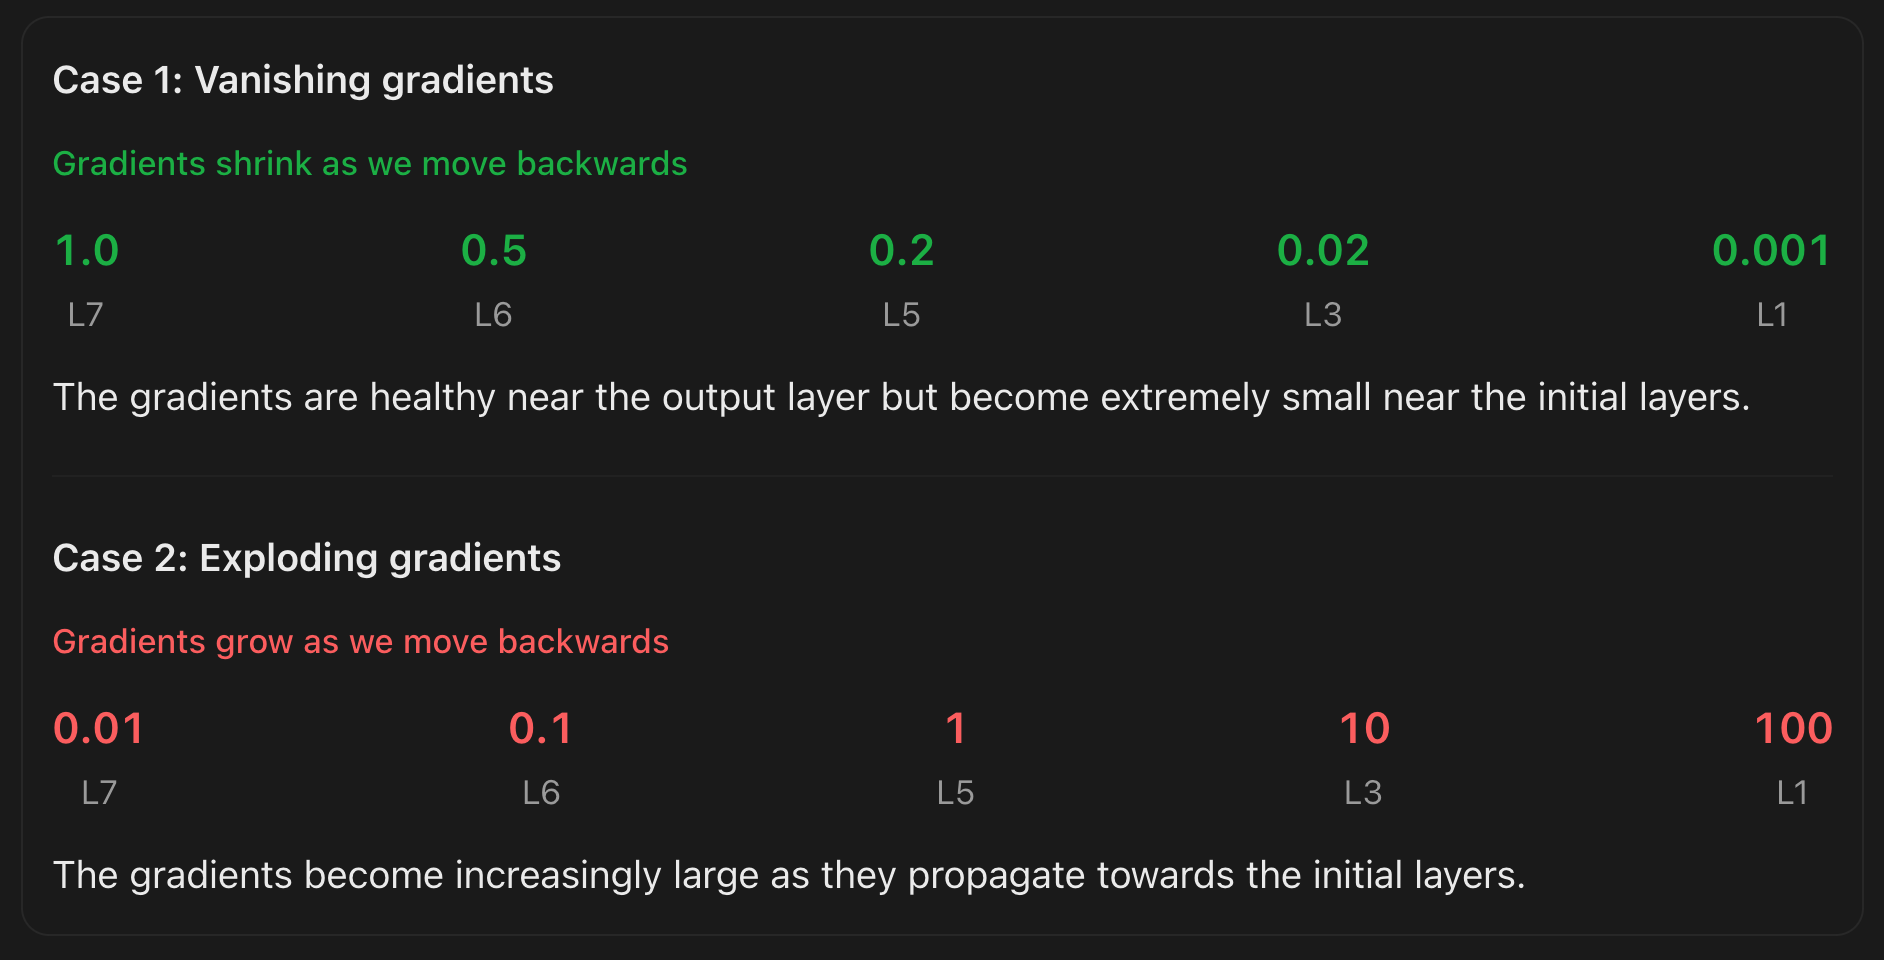

The gradients become increasingly large as they propagate towards the initial layers.

### **What about your second scenario?**

Suppose gradients are healthy in Layer 1 but extremely small in Layer 7.

That is also a gradient magnitude imbalance, but it is **not the usual meaning of vanishing gradients during backpropagation**.

The important thing to remember:

**Vanishing gradients means gradients become progressively smaller as they travel backwards from the output layer towards the input layer.**

Why does this matter? Because the initial layers receive almost no gradient signal, so their weights barely update. This makes learning difficult, particularly in deep networks.

weight   (27, 10) | mean +0.000837 | std 1.002593e-02 | grad:data ratio 1.002346e-02
weight  (30, 100) | mean -0.000012 | std 8.433931e-03 | grad:data ratio 2.695509e-02
weight (100, 100) | mean -0.000007 | std 7.231344e-03 | grad:data ratio 4.298102e-02
weight (100, 100) | mean +0.000066 | std 6.237132e-03 | grad:data ratio 3.675425e-02
weight (100, 100) | mean +0.000009 | std 6.353627e-03 | grad:data ratio 3.761949e-02
weight (100, 100) | mean +0.000094 | std 5.404349e-03 | grad:data ratio 3.208924e-02
weight  (100, 27) | mean +0.000000 | std 2.309205e-02 | grad:data ratio 3.210137e-01


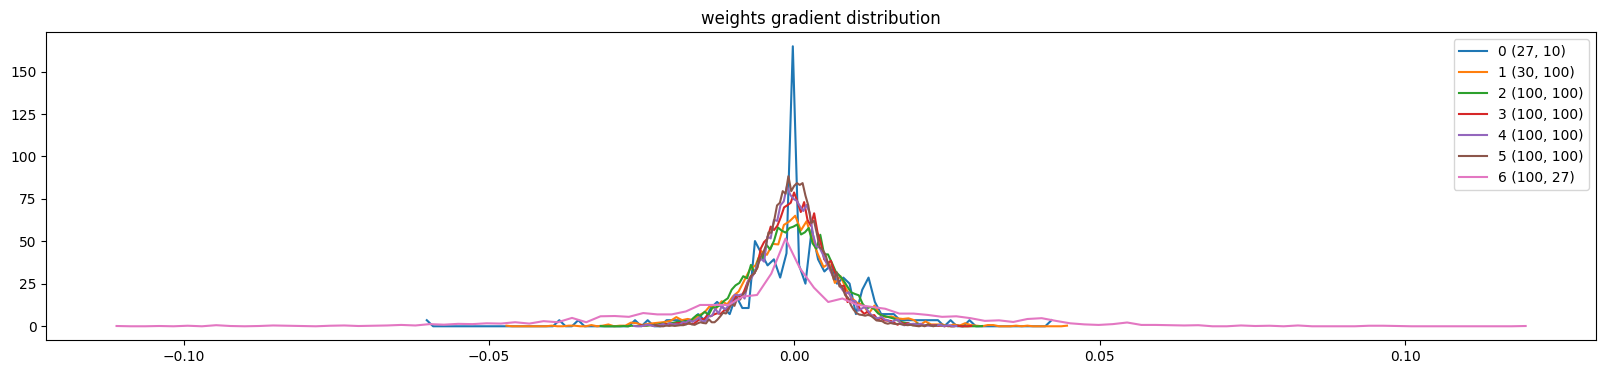

In [36]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i,p in enumerate(parameters):
  t = p.grad
  if p.ndim == 2:
    print('weight %10s | mean %+f | std %e | grad:data ratio %e' % (tuple(p.shape), t.mean(), t.std(), t.std() / p.std()))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'{i} {tuple(p.shape)}')
plt.legend(legends)
plt.title('weights gradient distribution');

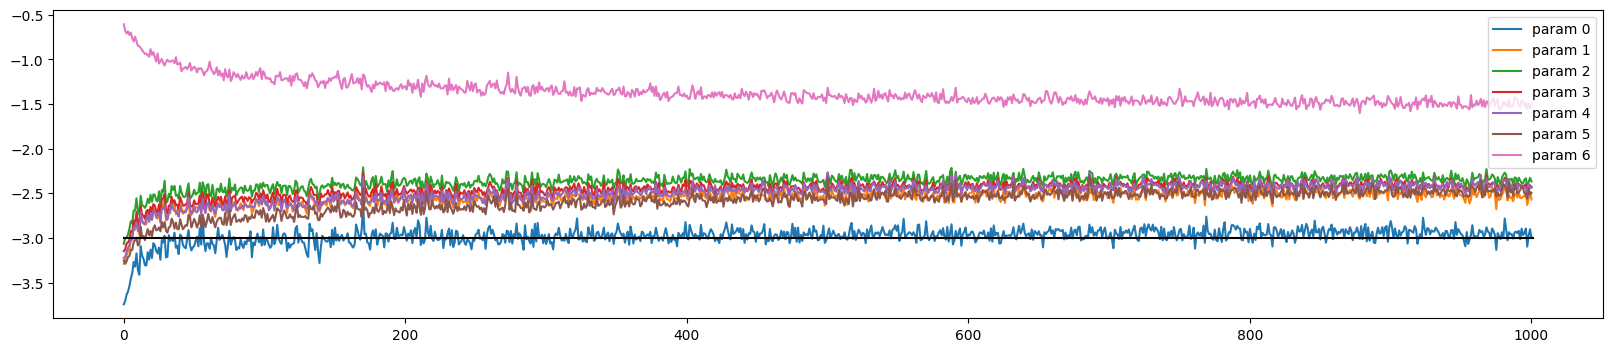

In [37]:
plt.figure(figsize=(20, 4))
legends = []
for i,p in enumerate(parameters):
  if p.ndim == 2:
    plt.plot([ud[j][i] for j in range(len(ud))])
    legends.append('param %d' % i)
plt.plot([0, len(ud)], [-3, -3], 'k') # these ratios should be ~1e-3, indicate on plot
plt.legend(legends);


## 26. Monitoring Parameters, Gradients, and Update-to-Data Ratios

After examining activation and gradient distributions, we now look at the parameters themselves and how they change during optimization.

The goal is to understand whether all layers are training at a reasonable rate and whether any particular layer is behaving abnormally.

### 1. Visualizing Parameter Statistics

We examine every parameter tensor in the network, starting from the embedding matrix and moving through the linear layers to the final output layer.

For each tensor, we inspect:

- Shape of the tensor.
- Mean and standard deviation.
- Histogram of its values.
- Gradient statistics.

This helps us identify layers whose parameter or gradient distributions look unusual.

### 2. Gradient-to-Data Ratio

One useful metric is the ratio between the standard deviation of the gradients and the standard deviation of the actual parameter values:

$$
\text{Gradient-to-Data Ratio}
=
\frac{\operatorname{std}(\text{grad})}
{\operatorname{std}(\text{data})}
$$

Why is this useful?

During stochastic gradient descent, our update is:

$$
\text{update} = -\text{learning rate} \times \text{gradient}
$$

If the gradients are very large compared to the parameter values, the updates might be too large.

In the current experiment, most parameter gradients have standard deviations around $10^{-3}$, while the final output layer has gradients around $10^{-2}$.

Therefore, the final layer's gradients are approximately 10 times larger than those of the other layers.

This means that, initially, the final layer is effectively training faster than the other layers under simple SGD.

Interestingly, this imbalance partially corrects itself after approximately 1,000 training iterations as the final layer's weights adapt.

### 3. Why Is the Final Layer an Outlier?

Recall that during initialization, we deliberately scaled down the final layer's weights:

```python
with torch.no_grad():
    layers[-1].weight *= 0.1
```

We did this to prevent the output layer from producing excessively confident predictions.

However, this also makes the actual parameter values in the final layer relatively small.

Consequently, its gradients become large relative to its parameter values.

This is why the final layer initially behaves differently from the other layers.

### 4. Update-to-Data Ratio: A More Useful Metric

The gradient-to-data ratio is useful, but it does not tell us exactly how much the parameters will change during optimization.

What actually matters is the size of the update relative to the parameter values.

Therefore, we introduce the **update-to-data ratio**:

$$
\text{Update-to-Data Ratio}
=
\frac{\operatorname{std}(\text{update})}
{\operatorname{std}(\text{data})}
$$

Since:

$$
\text{update} = -\text{learning rate}\times\text{gradient}
$$

We can calculate:

$$
\boxed{
\text{Update-to-Data Ratio}
=
\frac{
\operatorname{std}(\text{learning rate}\times\text{gradient})
}{
\operatorname{std}(\text{parameter values})
}
}
$$

We take the base-10 logarithm to make the values easier to visualize:

$$
\log_{10}(\text{Update-to-Data Ratio})
$$

### 5. Implementing the Update-to-Data Ratio

We maintain a list called `ud` to track this ratio for every parameter at every training iteration.

```python
ud = []

# Inside the optimization loop:
with torch.no_grad():
    ud.append([
        ((lr * p.grad).std() / p.data.std()).log10().item()
        for p in parameters
    ])
```

Each iteration records the update-to-data ratio for every parameter tensor.

We can then plot these values over training iterations to see how the update scales evolve.

For a plot focusing only on weight matrices, we can filter parameters by dimensionality:

```python
# Plot only 2D parameter tensors (weight matrices)
for i, p in enumerate(parameters):
    if p.ndim == 2:
        plt.plot([x[i] for x in ud])
```

### 6. What Is a Good Update-to-Data Ratio?

Karpathy uses approximately $10^{-3}$ as a useful reference point.

On the logarithmic scale:

$$
\log_{10}(10^{-3}) = -3
$$

This means that the standard deviation of the parameter update is approximately one-thousandth of the standard deviation of the parameter values.

Interpretation:

| Log update-to-data ratio | Interpretation |
|---|---|
| Around -3 | Reasonable reference point |
| Much below -3 | Updates may be too small; training could be slow |
| Around -1 | Updates are relatively large; parameters change substantially |
| Positive values | Updates can be extremely large relative to parameter values |

These are practical guidelines, not strict mathematical boundaries.

### 7. What Happens When the Learning Rate Is Too Small?

Karpathy demonstrates this by reducing the learning rate to:

```python
lr = 1e-3
```

The update-to-data ratio becomes much smaller.

The updates are approximately 10,000 times smaller than the parameter values in magnitude:

$$
\text{Update-to-Data Ratio} \approx 10^{-4}
$$

Taking the logarithm:

$$
\log_{10}(10^{-4}) = -4
$$

This indicates that the parameters are changing very slowly.

Therefore, the update-to-data ratio can help us identify an excessively small learning rate.

### 8. Choosing a Reasonable Learning Rate

In the demonstrated experiment, the update ratios stabilize around $10^{-2.5}$, slightly above the reference value of $10^{-3}$.

Karpathy considers this a reasonably good learning rate setting.

The important thing is to monitor how these ratios evolve over time and check whether any parameter tensors are receiving updates that are disproportionately large or small.

**Key takeaway:** Rather than looking only at gradient magnitudes, monitor the actual parameter updates relative to parameter values. The update-to-data ratio provides a useful way to diagnose learning rates and identify layers that are training too slowly or changing too aggressively.

---

## 27. Important Context: The Network Used in This Experiment

The supplied code defines a `BatchNorm1d` implementation with:

- Trainable `gamma` and `beta`.
- Running mean and variance.
- Exponential moving average updates.
- Separate behavior for training and inference.

However, the current `layers` list contains only `Linear` and `Tanh` layers. Batch normalization is defined but is not actually inserted into this particular network.

The network is a deep MLP with five hidden `Tanh` layers:

```python
layers = [
    Linear(n_embed * block_size, n_hidden, bias=False), Tanh(),
    Linear(n_hidden, n_hidden, bias=False), Tanh(),
    Linear(n_hidden, n_hidden, bias=False), Tanh(),
    Linear(n_hidden, n_hidden, bias=False), Tanh(),
    Linear(n_hidden, n_hidden, bias=False), Tanh(),
    Linear(n_hidden, vocab_size, bias=False)
]
```

The initialization applies a gain of $5/3$ to the hidden linear layers and scales down the final output layer:

```python
with torch.no_grad():
    layers[-1].weight *= 0.1

    for layer in layers[:-1]:
        if isinstance(layer, Linear):
            layer.weight *= 5/3
```

This is the setup in which we have been studying activation distributions, gradient distributions, parameter statistics, and update-to-data ratios.


## Let's now Introduce BatchNorm into the mix

In [40]:
n_embed = 10 # the dimensionality of the character embedding vectors
n_hidden = 100 # the number of neurons in the hidden layer of the MLP
g = torch.Generator().manual_seed(2147483647)

C = torch.randn((vocab_size, n_embed),              generator=g)

layers = [
    Linear(n_embed * block_size, n_hidden, bias = False), BatchNorm1d(n_hidden), Tanh(),
    Linear(n_hidden, n_hidden, bias = False), BatchNorm1d(n_hidden), Tanh(),
    Linear(n_hidden, n_hidden, bias = False), BatchNorm1d(n_hidden), Tanh(),
    Linear(n_hidden, n_hidden, bias = False), BatchNorm1d(n_hidden), Tanh(),
    Linear(n_hidden, n_hidden, bias = False), BatchNorm1d(n_hidden), Tanh(),
    Linear(n_hidden, vocab_size, bias = False), BatchNorm1d(vocab_size),
]


In [41]:
with torch.no_grad():
    # last layer: make less confident
    layers[-1].gamma *= 0.1 # Because the last layer is BatchNorm, we'd not be changing the weight to make the soft max less confident, we'd be changing the gamma
    #layers[-1].weight *= 0.1
    # all other layers: apply gain
    for layer in layers[:-1]:
        if isinstance(layer, Linear):
            layer.weight *= 1 #5/3

parameters = [C] + [p for layer in layers for p in layer.parameters()]
print(sum(p.nelement() for p in parameters))     # number of parametrs in total
for p in parameters:
    p.requires_grad = True

47024


**Short version:** BatchNorm undoes any scaling of the weight that comes before it. That makes `weight *= 0.1` useless, so the only knob left that controls how big the logits are is `gamma`.

## Why we shrink the last layer at all

The output of the last layer is the logits, which go into softmax and cross-entropy. At initialization we want the logits close to 0, so softmax gives a roughly uniform guess over 27 characters:

$$L \approx -\ln\tfrac{1}{27} \approx 3.30$$

Large random logits mean confident wrong guesses. The loss then starts high, and the first few thousand steps go to squashing the logits (the "hockey stick" shape in the loss curve). With roughly Gaussian logits of standard deviation $\sigma$, the starting loss is about $\ln 27 + \sigma^2/2$:

| Logit std $\sigma$ | Starting loss |
|---|---|
| 1.0 | ≈ 3.80 |
| 0.1 | ≈ 3.30 (close to the ideal) |

## Before BatchNorm: scale `W`

Previously the last layer was just $z = hW$. Scaling $W$ by 0.1 scales every logit by 0.1, so that worked.

## With BatchNorm last: scaling `W` gets cancelled

The last two layers are now Linear followed by BatchNorm. For each output feature $j$ (one per character), over the batch:

$$z = hW, \qquad \hat z_j = \frac{z_j - \mu_j}{\sqrt{\sigma_j^2 + \epsilon}}, \qquad \text{logit}_j = \gamma_j \hat z_j + \beta_j$$

Now try `W *= 0.1`:
- $z_j$ becomes $0.1\,z_j$.
- The batch mean $\mu_j$ becomes $0.1\,\mu_j$, and the batch std $\sigma_j$ becomes $0.1\,\sigma_j$.
- $\hat z_j = \dfrac{0.1(z_j - \mu_j)}{0.1\,\sigma_j} =$ **the same as before**.

The normalization step cancels the 0.1. Whatever scale `W` has, $\hat z_j$ always comes out with mean 0 and std 1 per feature (ignoring the tiny $\epsilon$).

So the logits' size is set entirely by $\gamma_j$ (the scale) and $\beta_j$ (the shift). At init $\gamma = 1$ and $\beta = 0$, so each logit column has std 1, which is the 3.80 row in the table. `gamma *= 0.1` makes the std 0.1, which brings you back to ≈ 3.30.

## The same reasoning applies to the 5/3 gain

Every hidden `Linear` is followed by `BatchNorm1d` before its `Tanh`. So `weight *= 5/3` gets normalized away in the forward pass too. The thing that controls how saturated tanh is now is that BatchNorm's $\gamma$, not the Linear gain. This is why BatchNorm makes networks much less sensitive to initialization. The gain is mostly left over from the version without BatchNorm.

It still has a small effect in the backward pass: if $W$ is scaled by $s$, $\partial L/\partial W$ scales by $1/s$. That changes the effective learning rate for those weights. You'll see it in Karpathy's update-to-data ratio plot (your `ud` list).

The same cancellation is why the Linear layers have `bias=False`. BatchNorm subtracts $\mu_j$, which wipes out any bias added before it, and $\beta$ does the bias's job instead.

In [42]:
# same optimization as last time
max_steps = 200000
batch_size = 32
lossi = []
ud = []

for i in range(max_steps):

    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size,), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix] # batch X, Y

    # forward pass
    emb = C[Xb] #embed characters into vectors
    x = emb.view(emb.shape[0], -1) # concatenate the vectors
    for layer in layers:
        x = layer(x)
    loss = F.cross_entropy(x, Yb) # loss function

    # backward pass
    for layer in layers:
        layer.out.retain_grad() # AFTER_DEBUG: would take out retain_graph
        # Woudldn't this create issues because we need to zero out the gradients before each loop. Where is this stored? is this stored in some separate place ?
        # Ans - This won't retain the gradients on the next iteration. This only retains the gradients after the last iteration. Check below for more

    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 150000 else 0.01 # step learning rate decay
    for p in parameters:
        p.data += -lr * p.grad

    # track stats
    if i % 10000 == 0: # print every once in a while
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())
    with torch.no_grad():
        ud.append([((lr*p.grad).std() / p.data.std()).log10().item() for p in parameters])


    if i >= 1000:
        break # AFTER_DEBUG: would take out obviously to run full optimization

      0/ 200000: 3.2870


layer 2 (      Tanh): mean -0.00, std 0.63, saturated: 2.62%
layer 5 (      Tanh): mean +0.00, std 0.64, saturated: 2.47%
layer 8 (      Tanh): mean -0.00, std 0.64, saturated: 2.16%
layer 11 (      Tanh): mean +0.00, std 0.65, saturated: 1.81%
layer 14 (      Tanh): mean -0.00, std 0.65, saturated: 1.78%


Text(0.5, 1.0, 'activation distribution')

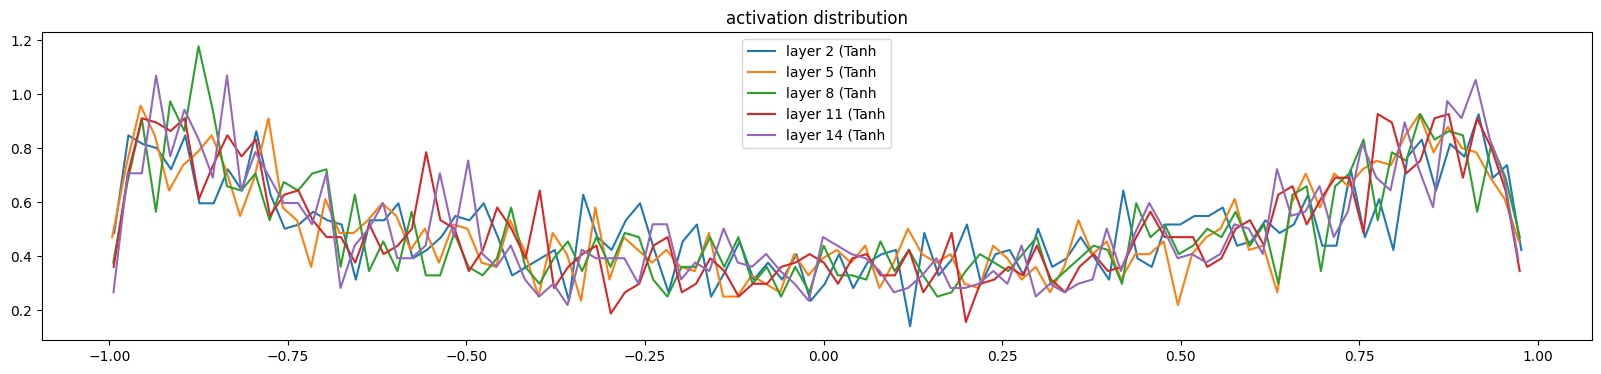

In [43]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out
    print('layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%' % (i, layer.__class__.__name__, t.mean(), t.std(), (t.abs() > 0.97).float().mean()*100))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends);
plt.title('activation distribution')

layer 2 (      Tanh): mean +0.000000, std 3.682956e-03
layer 5 (      Tanh): mean -0.000000, std 3.262610e-03
layer 8 (      Tanh): mean +0.000000, std 2.973731e-03
layer 11 (      Tanh): mean +0.000000, std 2.741112e-03
layer 14 (      Tanh): mean +0.000000, std 2.584294e-03


Text(0.5, 1.0, 'gradient distribution')

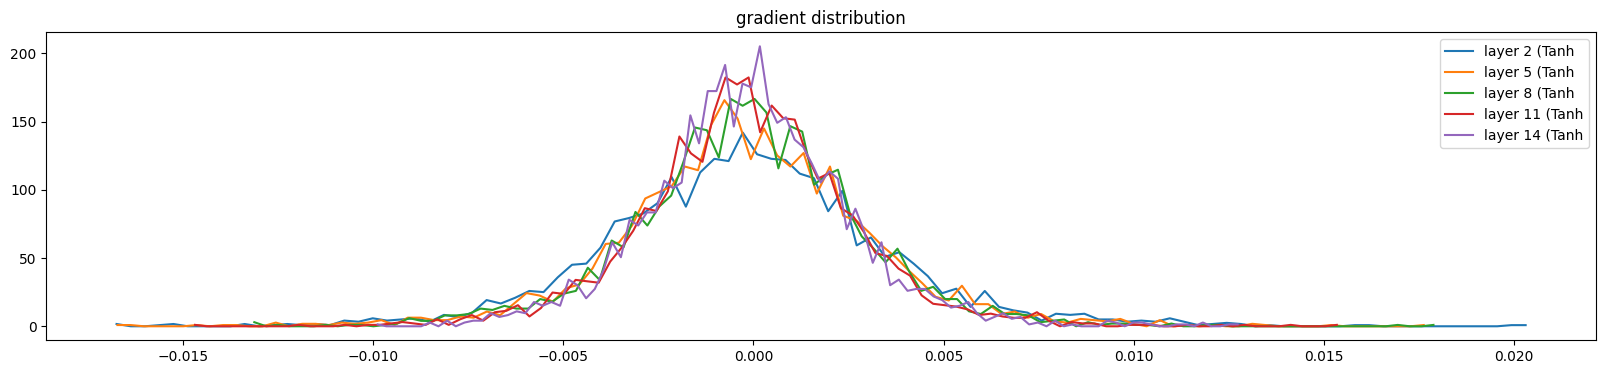

In [44]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out.grad
    print('layer %d (%10s): mean %+f, std %e' % (i, layer.__class__.__name__, t.mean(), t.std()))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends);
plt.title('gradient distribution')


weight   (27, 10) | mean -0.000000 | std 1.019887e-02 | grad:data ratio 1.018848e-02
weight  (30, 100) | mean +0.000092 | std 8.238435e-03 | grad:data ratio 2.635841e-02
weight (100, 100) | mean +0.000031 | std 7.318117e-03 | grad:data ratio 4.377148e-02
weight (100, 100) | mean -0.000019 | std 6.662027e-03 | grad:data ratio 3.949898e-02
weight (100, 100) | mean -0.000019 | std 5.821518e-03 | grad:data ratio 3.468162e-02
weight (100, 100) | mean +0.000053 | std 5.445299e-03 | grad:data ratio 3.243369e-02
weight  (100, 27) | mean -0.000165 | std 1.046845e-02 | grad:data ratio 6.281269e-02


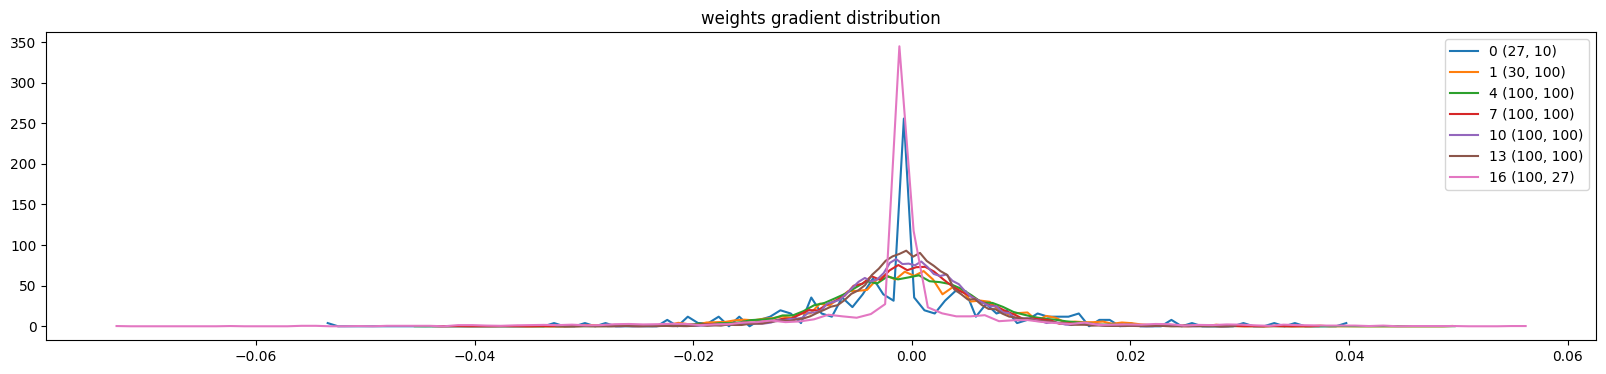

In [45]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i,p in enumerate(parameters):
  t = p.grad
  if p.ndim == 2:
    print('weight %10s | mean %+f | std %e | grad:data ratio %e' % (tuple(p.shape), t.mean(), t.std(), t.std() / p.std()))
    hy, hx = torch.histogram(t, density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'{i} {tuple(p.shape)}')
plt.legend(legends)
plt.title('weights gradient distribution');

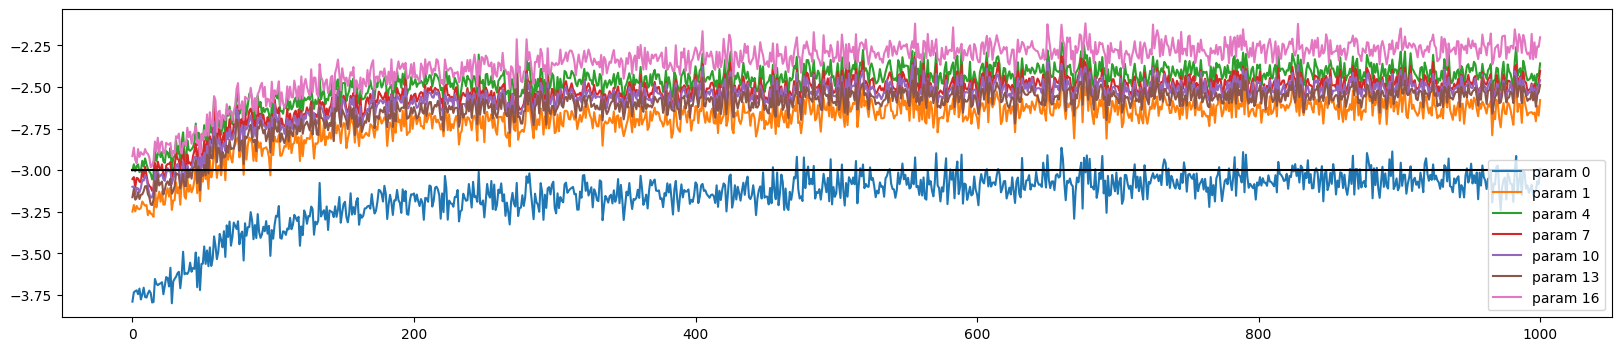

In [46]:
plt.figure(figsize=(20, 4))
legends = []
for i,p in enumerate(parameters):
  if p.ndim == 2:
    plt.plot([ud[j][i] for j in range(len(ud))])
    legends.append('param %d' % i)
plt.plot([0, len(ud)], [-3, -3], 'k') # these ratios should be ~1e-3, indicate on plot
plt.legend(legends);

Your observation is the key one. With BatchNorm, the scale of $W$ disappears from the forward pass, but **it reappears as the effective learning rate**. The ud plot is the only one of your plots that measures learning rate, so it's the only one that moves.

## Why only ud moves: the ratio scales as $1/s^2$

Scale a weight that feeds into BatchNorm by $s$. The loss doesn't change: $L(sW) = L(W)$. Differentiating both sides with respect to $W$ gives

$$s\,\nabla L(sW) = \nabla L(W) \;\Rightarrow\; \nabla L(sW) = \tfrac{1}{s}\,\nabla L(W)$$

Plug that into what you track:

$$\text{ud} = \frac{\text{std}(\text{lr}\cdot\text{grad})}{\text{std}(W)} \;\propto\; \frac{1/s}{s} = \frac{1}{s^2}$$

With $s = 0.2$, the ratio is **25× larger**, which is $+1.4$ in log10. Your curves go from about −3 to about −1.6.

A correction to what you said: the weight gradient histogram does change. With $s = 0.2$ the gradients are 5× bigger. Matplotlib rescales the axes automatically, so the shape looks identical. Check the x-axis range and the printed `grad:data ratio` line, which should also go up by about 25×. The activation and activation-gradient plots really are unchanged, because those come after BatchNorm, where the scale has already been cancelled.

## What actually goes wrong: your `lr` isn't the learning rate you think

Each step changes $W$ by $\text{lr}\cdot\text{grad}$. What matters for BatchNorm-wrapped weights is the step size *relative to* $W$, because only the direction of $W$ affects the output. So the effective learning rate is

$$\text{lr}_{\text{eff}} \approx \frac{\text{lr}}{s^2}$$

| Weight scale $s$ | ud (log10) | Effective lr (with lr = 0.1) | What it does to training |
|---|---|---|---|
| 0.2 | ≈ −1.6 | ≈ 2.5 | Each step changes weights by a few percent. Updates are noisy and the loss plateaus higher. |
| 1 | ≈ −3 | 0.1 | The ~0.1% per step that Karpathy aims for |
| 5 | ≈ −4.4 | ≈ 0.004 | Weights barely move. Those layers are effectively frozen and training crawls. |

So $s$ is not harmless just because the forward pass ignores it. It silently turns your learning rate up or down by $s^2$, separately for each layer. That's the danger: different layers can end up learning at very different speeds while all your forward-pass plots look fine.

## A subtlety you can check on your plot

For a weight that BatchNorm makes scale-invariant, the gradient is always perpendicular to $W$. (Take $\frac{d}{ds}L(sW) = 0$ at $s = 1$, which gives $W \cdot \nabla L = 0$.) Every SGD step therefore makes $\|W\|$ **bigger**: $\|W + \Delta W\|^2 = \|W\|^2 + \|\Delta W\|^2$.

When $W$ starts small ($s = 0.2$), the large updates inflate $\|W\|$ quickly, and that lowers the effective learning rate. So the ud curves for $s = 0.2$ should **start high and drift downward** over training, partly correcting themselves. When $W$ starts large, there's no matching mechanism to shrink it, so that case stays slow. (Weight decay is what shrinks weights, which is why weight decay and BatchNorm interact in strange ways.)

## Prediction exercise

Before running anything, predict the ranking of final validation loss for $s = 0.2$, $1$ and $5$, each trained for 30k steps with your current `lr`. Then run all three and compare. Also look at whether the $s = 0.2$ ud curves slope downward.

In [ ]:
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  emb = C[x] # (N, block_size, n_embd)
  x = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
  for layer in layers:
    x = layer(x)
  loss = F.cross_entropy(x, y)
  print(split, loss.item())

# put layers into eval mode
for layer in layers:
  layer.training = False
split_loss('train')
split_loss('val')

In [ ]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):

    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      # forward pass the neural net
      emb = C[torch.tensor([context])] # (1,block_size,n_embd)
      x = emb.view(emb.shape[0], -1) # concatenate the vectors
      for layer in layers:
        x = layer(x)
      logits = x
      probs = F.softmax(logits, dim=1)
      # sample from the distribution
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      # shift the context window and track the samples
      context = context[1:] + [ix]
      out.append(ix)
      # if we sample the special '.' token, break
      if ix == 0:
        break

    print(''.join(itos[i] for i in out)) # decode and print the generated word